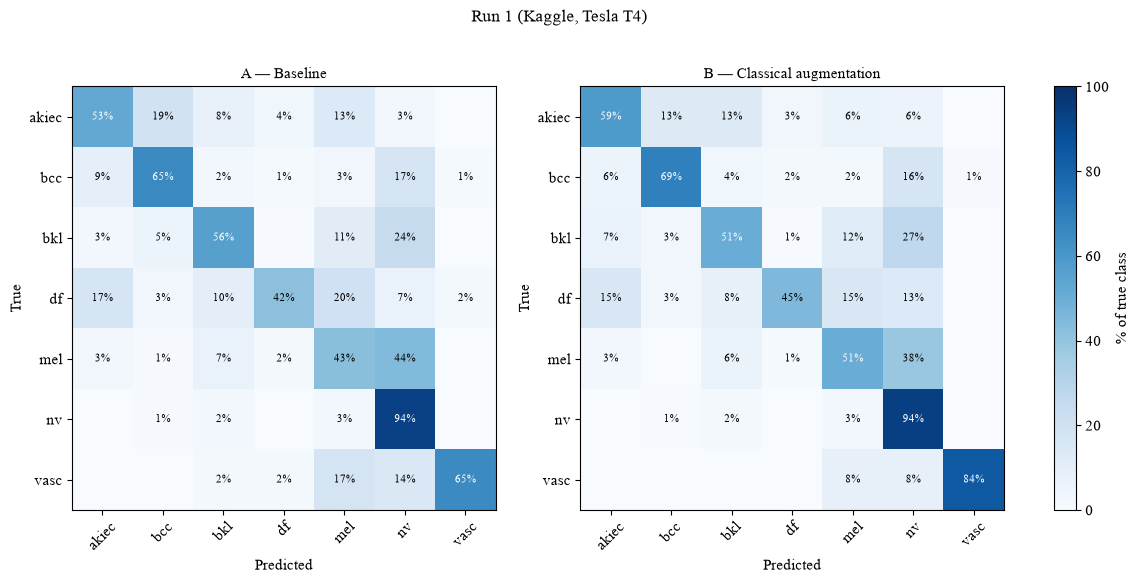


Run 1 (Kaggle, Tesla T4) — melanoma predicted as:
  akiec   A   3.4%   B   2.8%
  bcc     A   1.0%   B   0.2%
  bkl     A   7.0%   B   6.4%
  df      A   1.8%   B   1.4%
  mel     A  42.5%   B  50.7%
  nv      A  44.3%   B  38.3%


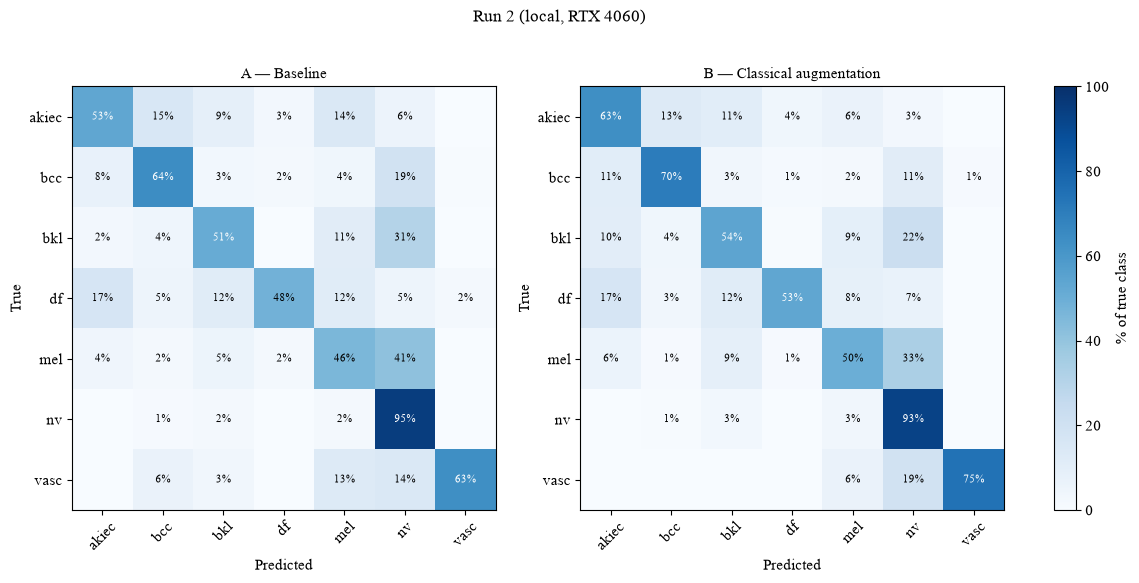


Run 2 (local, RTX 4060) — melanoma predicted as:
  akiec   A   4.0%   B   6.0%
  bcc     A   1.6%   B   0.8%
  bkl     A   5.4%   B   9.0%
  df      A   1.6%   B   0.8%
  mel     A  45.9%   B  49.9%
  nv      A  41.3%   B  33.3%


In [1]:
import os
os.chdir(r"D:\thesis")

import json, numpy as np, matplotlib as mpl, matplotlib.pyplot as plt
from src.data import CLASSES

mpl.rcParams.update({
    "font.family": "serif", "font.serif": ["Times New Roman"],
    "font.size": 11, "savefig.dpi": 300, "figure.dpi": 100,
    "savefig.bbox": "tight",
})

def load_cm(run, cond, seeds=(42, 43, 44)):
    cms = []
    for s in seeds:
        p = f"results/{run}/metrics/{cond}_seed{s}.json"
        cms.append(np.array(json.load(open(p))["confusion_matrix"]))
    cm = np.mean(cms, axis=0)
    return cm / cm.sum(axis=1, keepdims=True) * 100

for run, label in [("run1_cloud", "Run 1 (Kaggle, Tesla T4)"),
                   ("run2_local", "Run 2 (local, RTX 4060)")]:
    cm_A = load_cm(run, "A_baseline")
    cm_B = load_cm(run, "B_classical")

    fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
    for ax, cm, title in [(axes[0], cm_A, "A — Baseline"),
                          (axes[1], cm_B, "B — Classical augmentation")]:
        im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=100)
        ax.set_xticks(range(7)); ax.set_xticklabels(CLASSES, rotation=45)
        ax.set_yticks(range(7)); ax.set_yticklabels(CLASSES)
        ax.set_xlabel("Predicted"); ax.set_ylabel("True")
        ax.set_title(title, fontsize=11)
        for i in range(7):
            for j in range(7):
                if cm[i, j] >= 0.5:
                    ax.text(j, i, f"{cm[i,j]:.0f}%", ha="center", va="center",
                            fontsize=8, color="white" if cm[i, j] > 50 else "black")
    fig.colorbar(im, ax=axes, fraction=0.025, label="% of true class")
    fig.suptitle(label, fontsize=12, y=1.02)

    tag = "run1" if run == "run1_cloud" else "run2"
    plt.savefig(f"results/figures/fig07_confusion_matrices_{tag}.png")
    plt.show()

    mi = CLASSES.index("mel")
    print(f"\n{label} — melanoma predicted as:")
    for j, c in enumerate(CLASSES):
        if cm_A[mi, j] >= 0.5 or cm_B[mi, j] >= 0.5:
            print(f"  {c:6s}  A {cm_A[mi, j]:5.1f}%   B {cm_B[mi, j]:5.1f}%")